##  - Variable de control

#### Simulación de Procesos Financieros

José Armando Melchor Soto
 | 21/10/2026

---

### Libraries 

In [63]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.stats import norm

from warnings import filterwarnings
filterwarnings('ignore')

---

### Functions

In [64]:
np.random.seed(42)
def simular_MC_normal(S0, r, sigma, T, M, n):
    dt = T / n
    Z = np.random.normal(0, 1, (M, n))
    S = np.zeros((M, n + 1))
    S[:, 0] = S0

    for t in range(n):
        S[:, t + 1] = S[:, t] * np.exp((r - sigma**2 / 2) * dt + sigma * np.sqrt(dt) * Z[:, t])

    return S

def simular_MC_antithetica(S0, r, sigma, T, M, n):
    dt = T / n
    Z = np.random.normal(0, 1, (M // 2, n))
    Z_antithetica = -Z
    Z_total = np.vstack((Z, Z_antithetica))
    
    S = np.zeros((M, n + 1))
    S[:, 0] = S0

    for t in range(n):
        S[:, t + 1] = S[:, t] * np.exp((r - sigma**2 / 2) * dt + sigma * np.sqrt(dt) * Z_total[:, t])

    return S


def grafica_rutas(S, title, fechas):
    plt.figure(figsize=(12, 6))
    plt.plot(fechas, S.T, lw=1)
    plt.title(title)
    plt.xlabel('Fecha')
    plt.ylabel('Precio del activo')
    plt.xticks(rotation=45)
    plt.grid()
    plt.tight_layout()
    plt.show()


    
def grafica_histograma(payoffs, title):
    plt.figure(figsize=(10, 6))
    plt.hist(payoffs, bins=10, alpha=0.7, color='blue', edgecolor='black')
    plt.title(title)
    plt.xlabel('Payoff descontado')
    plt.ylabel('Frecuencia')
    plt.grid()
    plt.show()

---

In [65]:
tickets = ['AAPL', 'MSFT', 'NVDA','META', 'AMZN']

data = yf.download(tickets, start='2025-01-01', end='2026-01-01' , progress=False)['Close']

rets = np.log(data / data.shift(1)).dropna()

mu = rets.mean()
sigma = rets.std()

sim_date = {
    'start_date': '2026-01-01',
    'end_date': '2026-06-30'
}

S0 = data.iloc[-1]
r = rets.mean() * 252
sigma_anual = rets.std() * np.sqrt(252)
T = (pd.to_datetime(sim_date['end_date']) - pd.to_datetime(sim_date['start_date'])).days / 365
M, n = 50, 125

fechas = pd.bdate_range(start='2025-12-31', periods=n+1)

### Parámetros

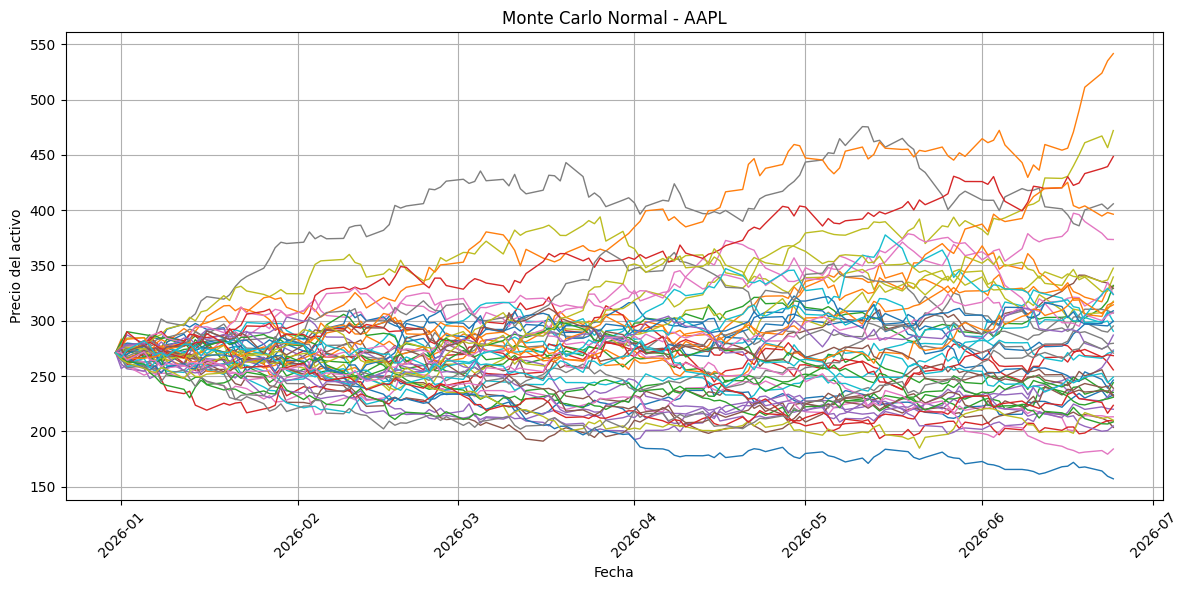

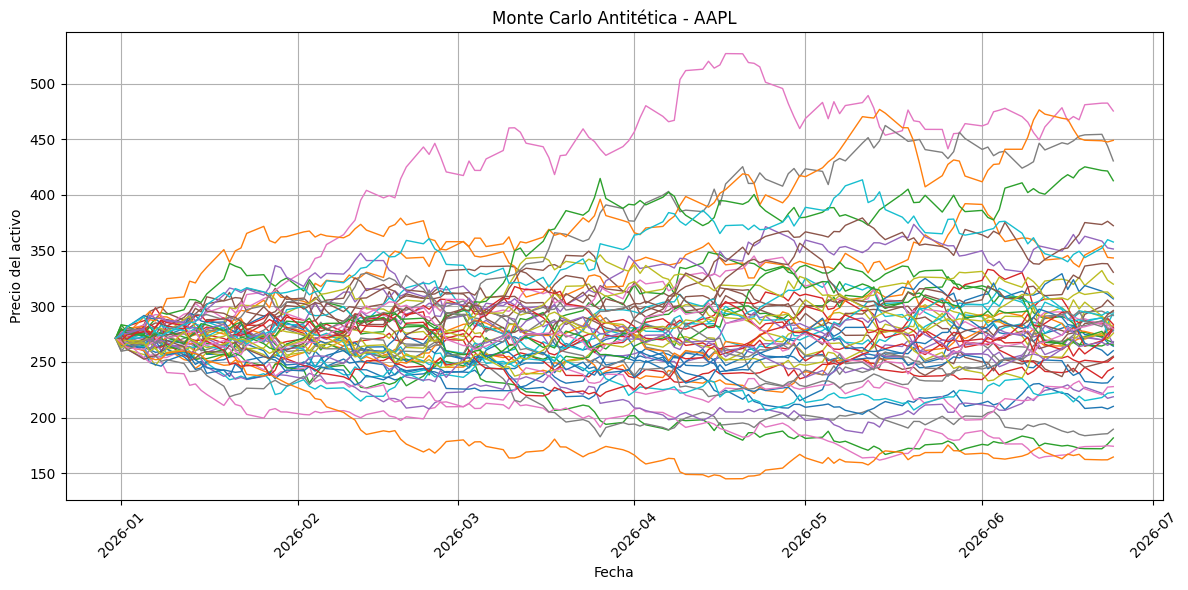

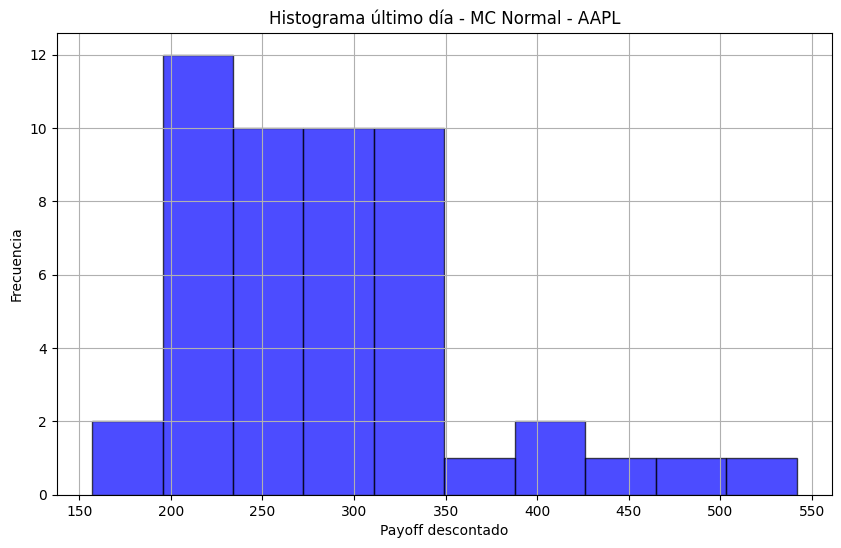

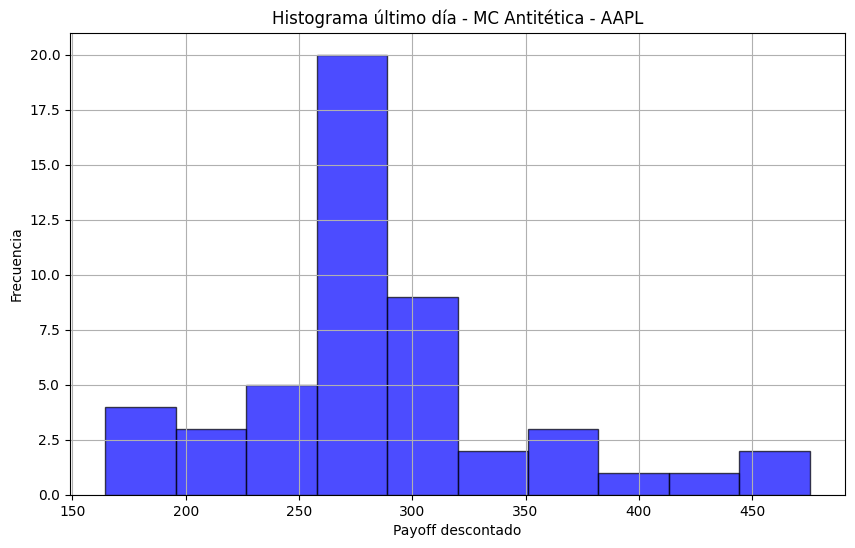

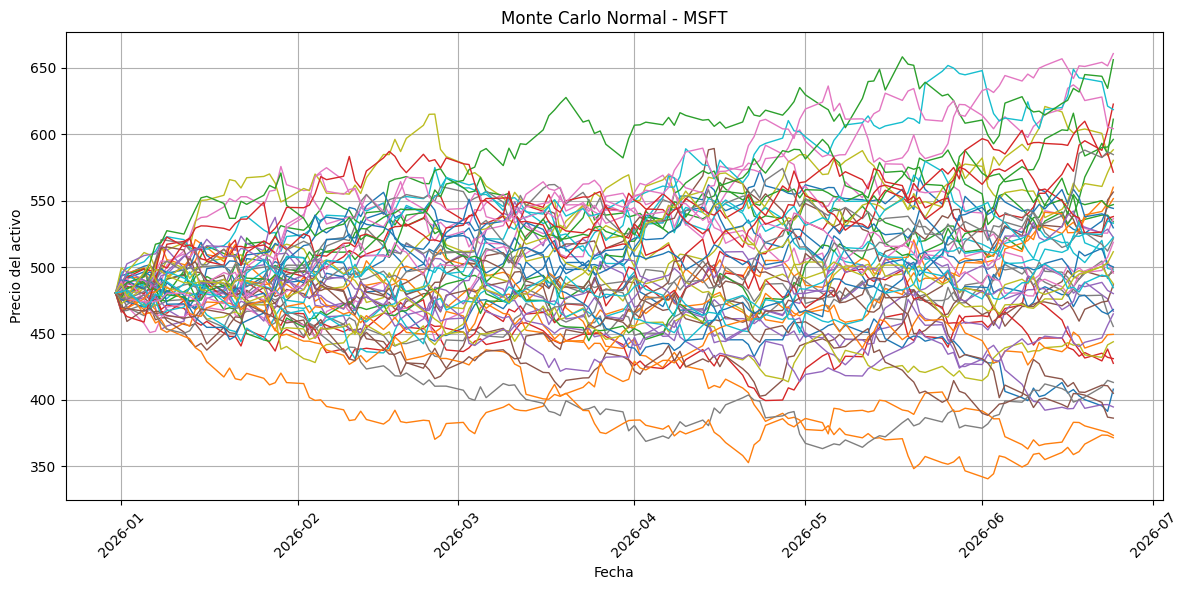

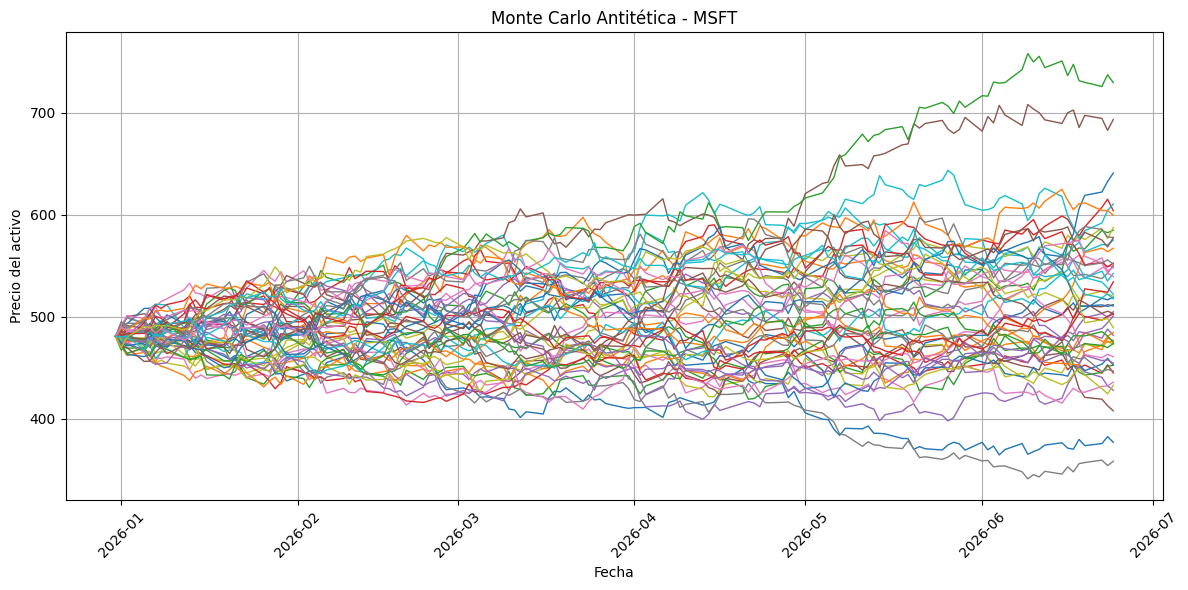

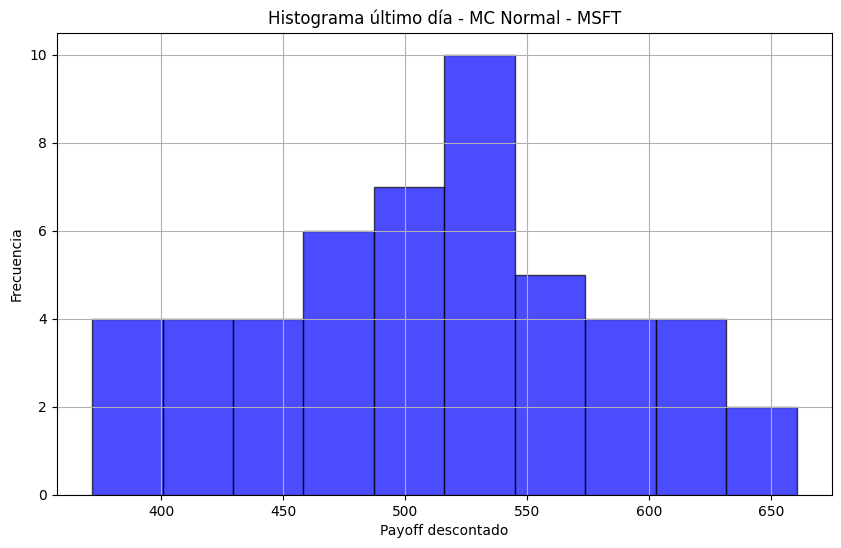

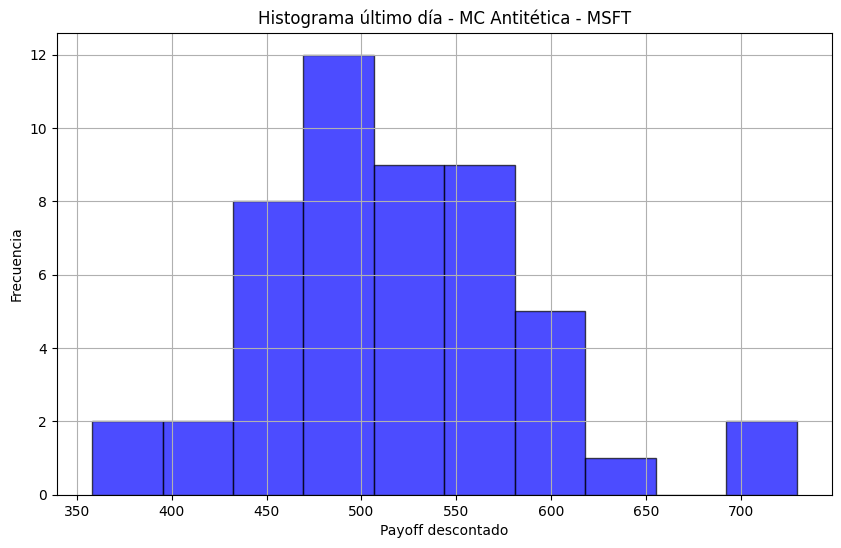

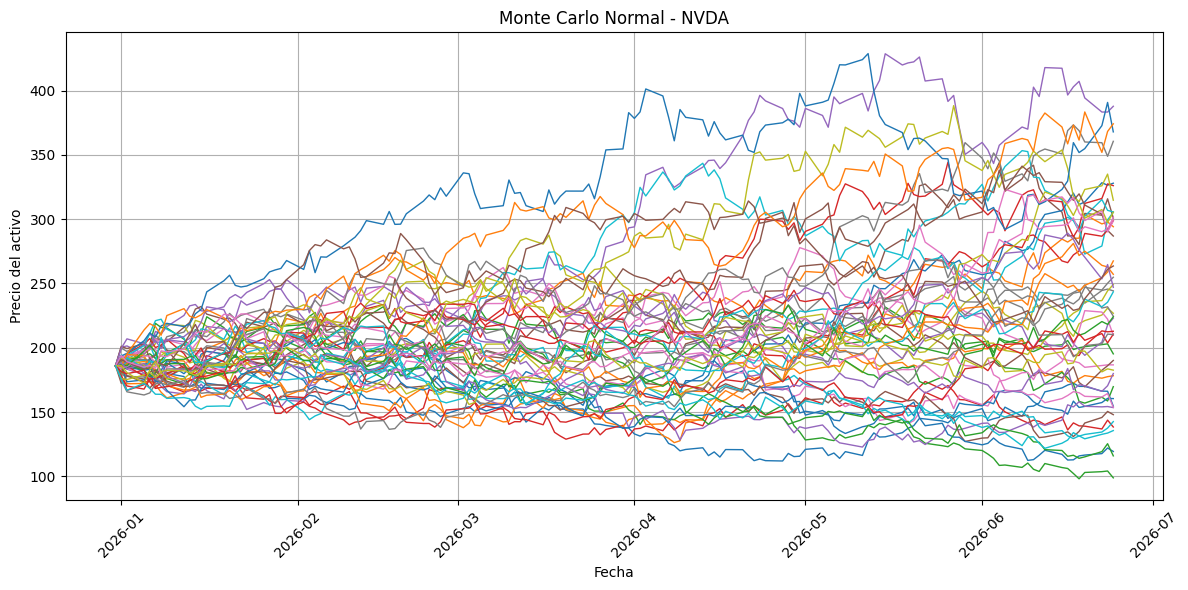

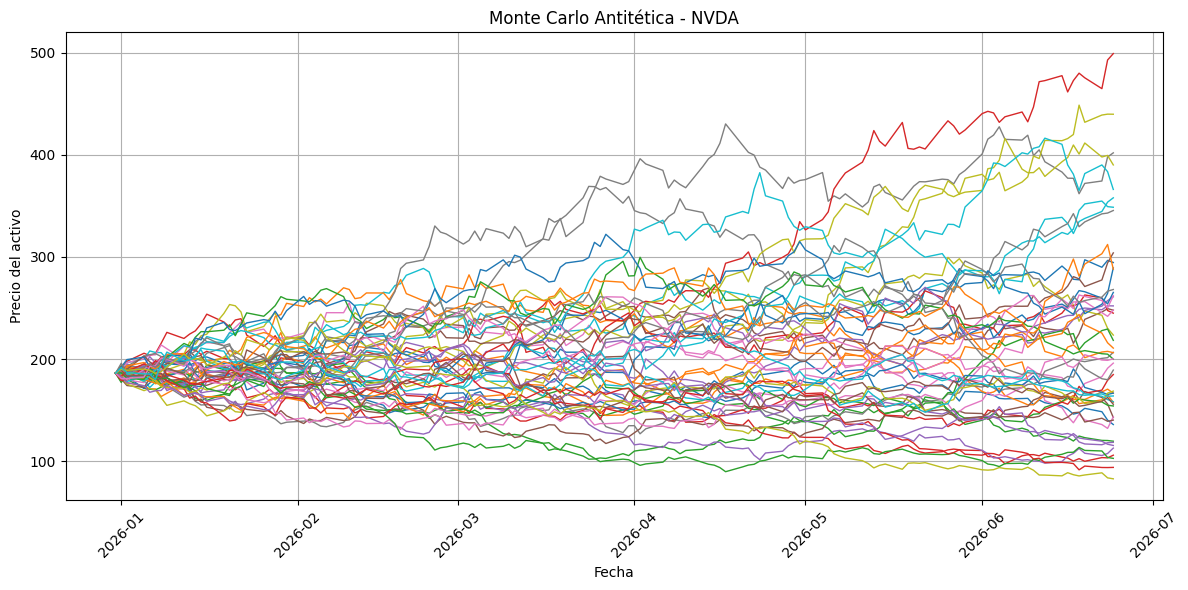

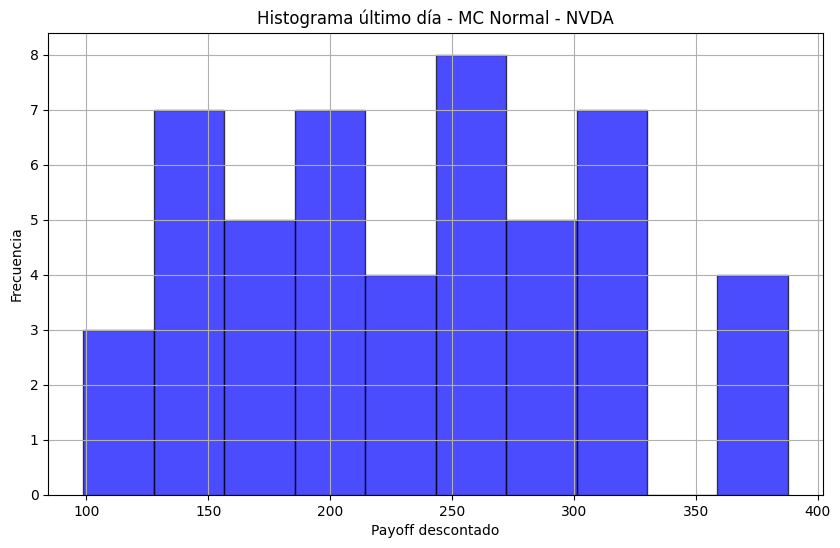

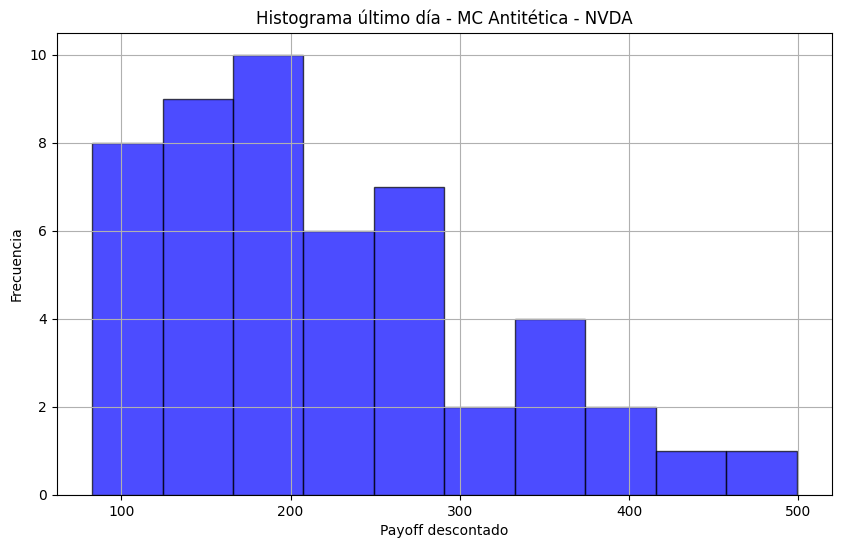

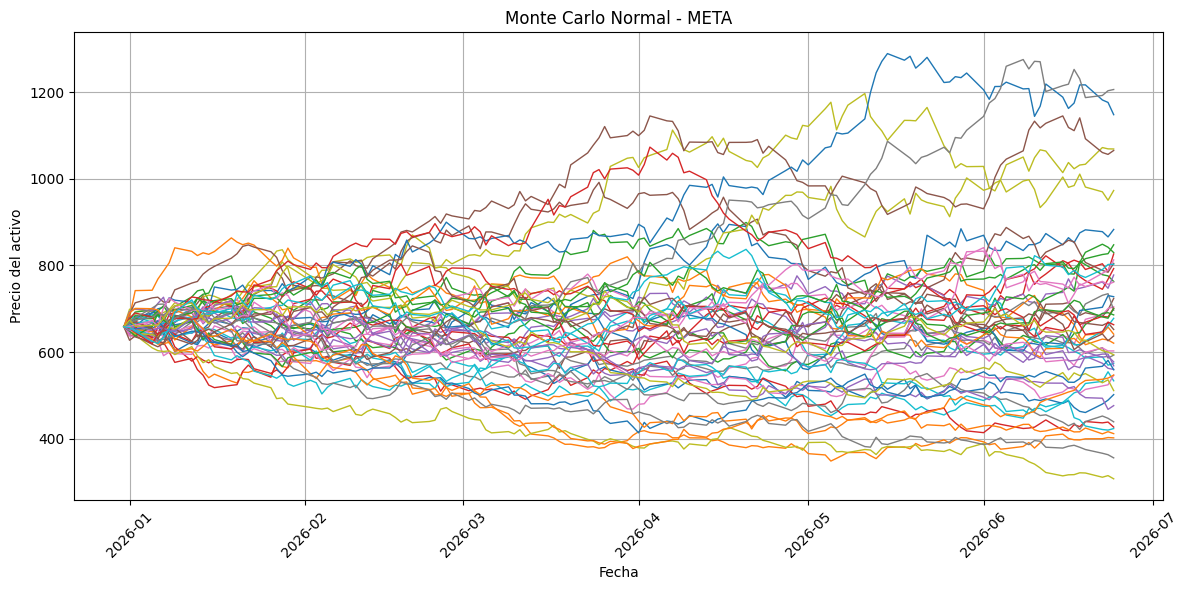

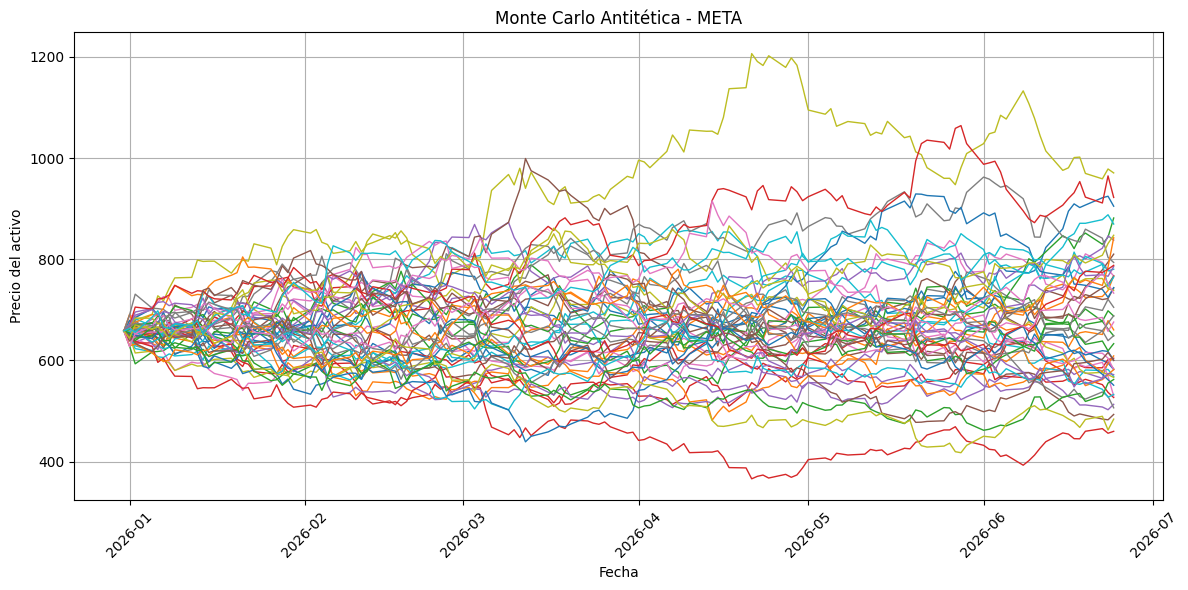

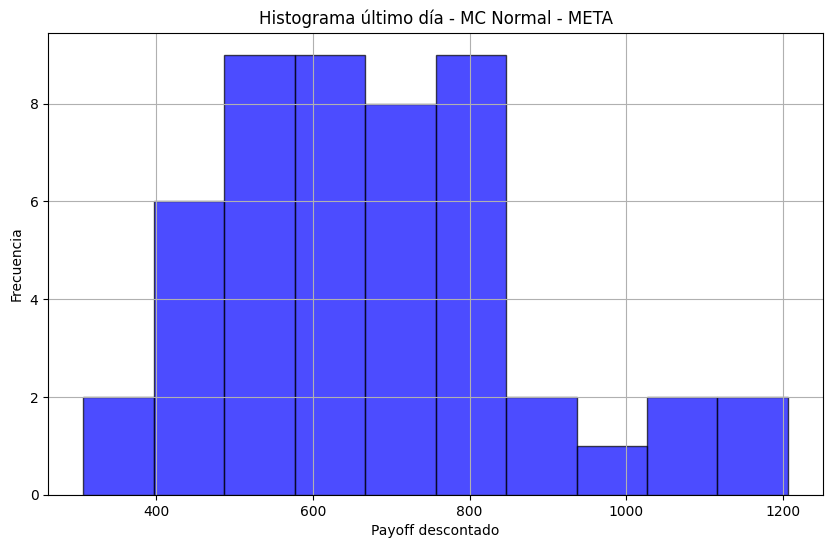

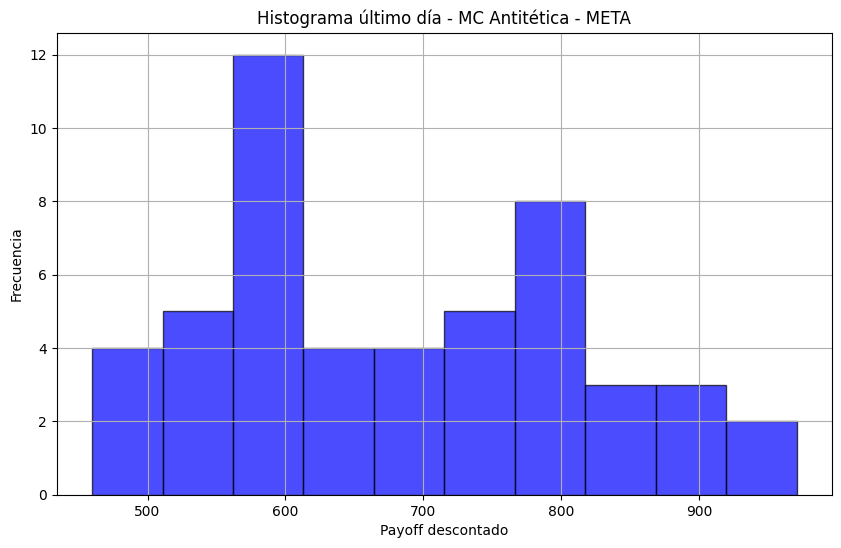

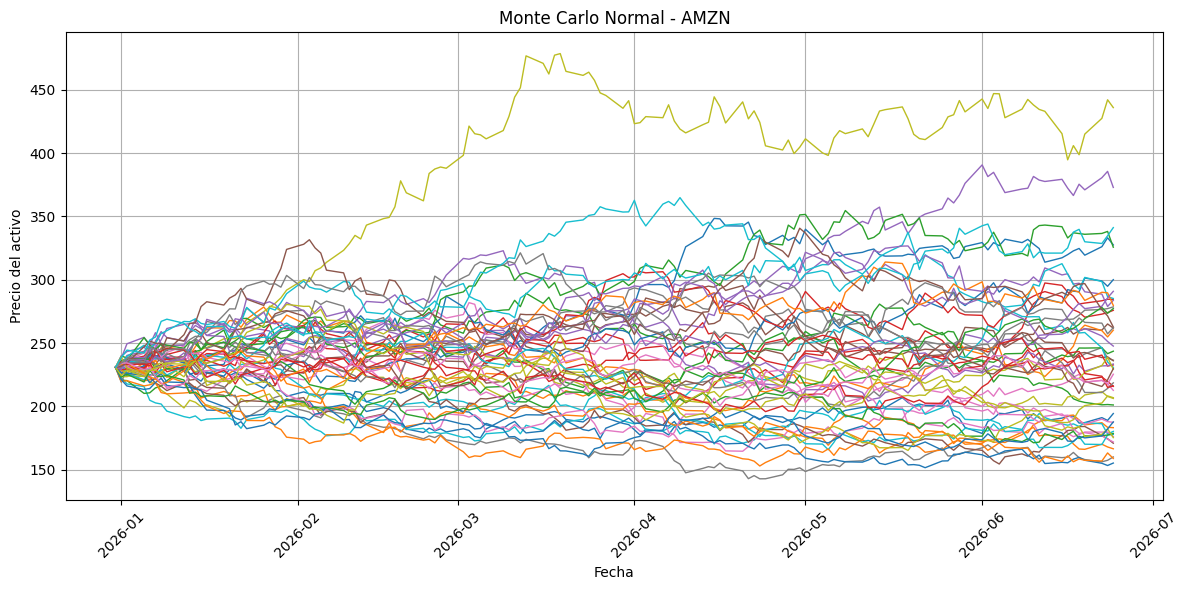

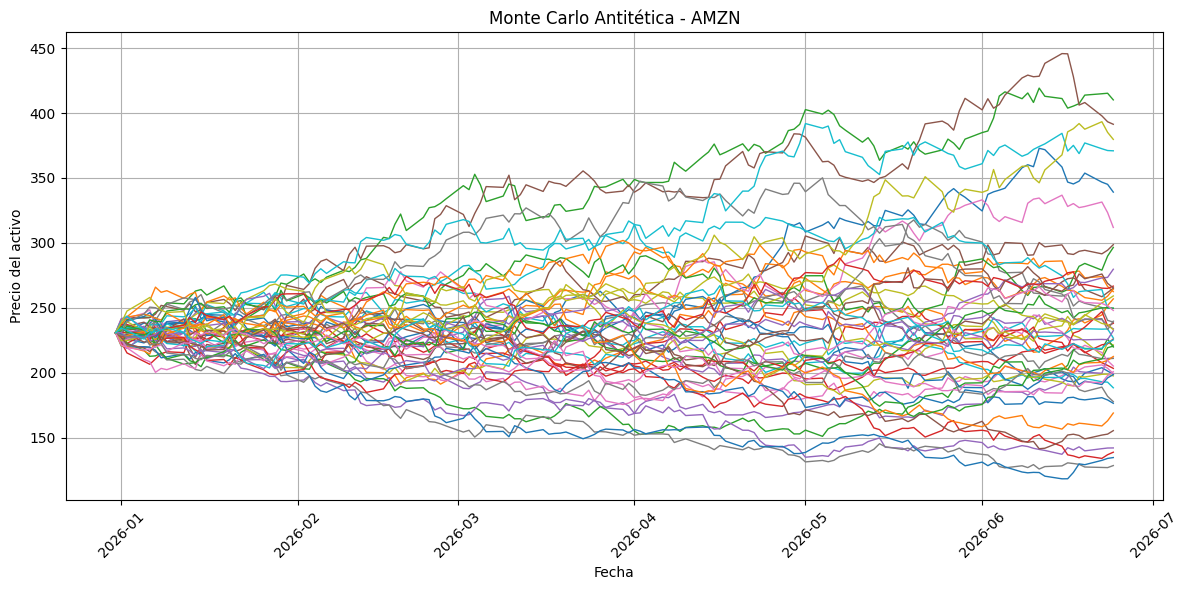

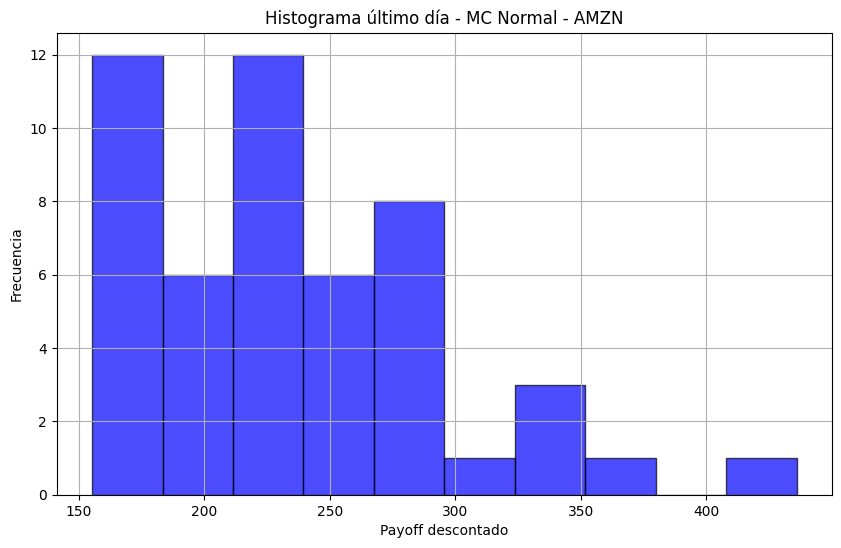

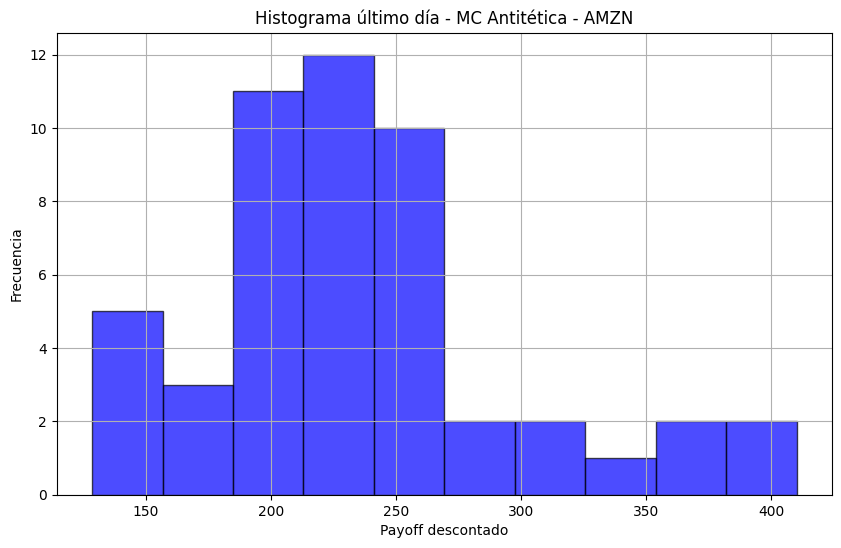

In [66]:

# Simular cada acción
rutas_normal = {ticker: simular_MC_normal(S0[ticker], r[ticker], sigma_anual[ticker], T, M, n) for ticker in tickets}
rutas_antitetica = {ticker: simular_MC_antithetica(S0[ticker], r[ticker], sigma_anual[ticker], T, M, n) for ticker in tickets}

# Graficar
for ticker in tickets:
    grafica_rutas(rutas_normal[ticker], f'Monte Carlo Normal - {ticker}', fechas)
    grafica_rutas(rutas_antitetica[ticker], f'Monte Carlo Antitética - {ticker}', fechas)
    grafica_histograma(rutas_normal[ticker][:, -1], f'Histograma último día - MC Normal - {ticker}')
    grafica_histograma(rutas_antitetica[ticker][:, -1], f'Histograma último día - MC Antitética - {ticker}')   
     

### Comparación Método MC

In [67]:
compare_results = pd.DataFrame({
    'Ticker': tickets,
    'S0': [S0[ticker] for ticker in tickets],
    'Precio Real Final': [data[ticker].iloc[-1] for ticker in tickets],
    'Mean Final MC Normal': [rutas_normal[ticker][:, -1].mean() for ticker in tickets],
    'Mean Final MC Antitética': [rutas_antitetica[ticker][:, -1].mean() for ticker in tickets],
    'Varianza MC Normal': [rutas_normal[ticker][:, -1].var(ddof=1) for ticker in tickets],
    'Varianza MC Antitética': [((rutas_antitetica[ticker][:M//2, -1] + rutas_antitetica[ticker][M//2:, -1]) / 2).var(ddof=1) for ticker in tickets],
    'Error MC Normal': [rutas_normal[ticker][:, -1].std(ddof=1) / np.sqrt(M) for ticker in tickets],
    'Error MC Antitética': [((rutas_antitetica[ticker][:M//2, -1] + rutas_antitetica[ticker][M//2:, -1]) / 2).std(ddof=1) / np.sqrt(M//2) for ticker in tickets]
})
compare_results

,Ticker,S0,Precio Real Final,Mean Final MC Normal,Mean Final MC Antitética,Varianza MC Normal,Varianza MC Antitética,Error MC Normal,Error MC Antitética
0,AAPL,271.122009,271.122009,286.838101,286.259589,5669.845165,126.687981,10.648798,2.251115
1,MSFT,480.571167,480.571167,510.120824,516.011670,5261.085142,60.801242,10.257763,1.559503
2,NVDA,186.064621,186.064621,234.551560,222.247134,5494.930050,513.567344,10.483253,4.532405
3,META,658.395081,658.395081,674.110848,680.319685,39103.805404,148.253372,27.965624,2.435187
4,AMZN,230.820007,230.820007,237.102281,237.382556,3521.367752,140.591917,8.392101,2.371429


### Comparar 6 meses 2026 

In [74]:
data_real_2026 = yf.download(tickets, start='2026-01-01', end='2026-07-01', progress=False)['Close']

precios_reales_2026 = data_real_2026.iloc[-1]

compare_results_2026 = pd.DataFrame({
    'Ticker': tickets,
    'Precio inicial': [data_real_2026[ticker].iloc[0] for ticker in tickets],
    'Precio real final': [precios_reales_2026[ticker] for ticker in tickets],
    'Media final MC Normal': [rutas_normal[ticker][:, -1].mean() for ticker in tickets],
    'Media final MC Antitética': [rutas_antitetica[ticker][:, -1].mean() for ticker in tickets],
    'Error MC Normal (%)': [abs(rutas_normal[ticker][:, -1].mean() - precios_reales_2026[ticker]) / precios_reales_2026[ticker] * 100 for ticker in tickets],
    'Error MC Antitética (%)': [abs(rutas_antitetica[ticker][:, -1].mean() - precios_reales_2026[ticker]) / precios_reales_2026[ticker] * 100 for ticker in tickets]
})

compare_results_2026.round(2)


,Ticker,Precio inicial,Precio real final,Media final MC Normal,Media final MC Antitética,Error MC Normal (%),Error MC Antitética (%)
0,AAPL,270.27,289.11,286.84,286.26,0.79,0.99
1,MSFT,469.96,372.32,510.12,516.01,37.01,38.59
2,NVDA,188.41,199.87,234.55,222.25,17.35,11.20
3,META,648.74,562.85,674.11,680.32,19.77,20.87
4,AMZN,226.50,238.34,237.10,237.38,0.52,0.40


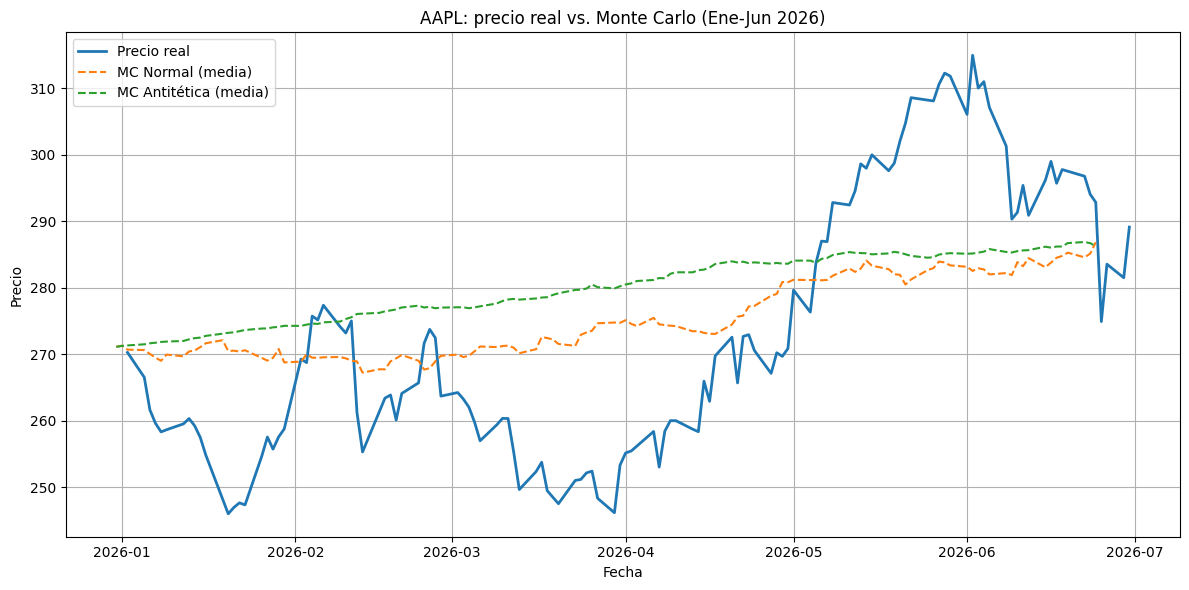

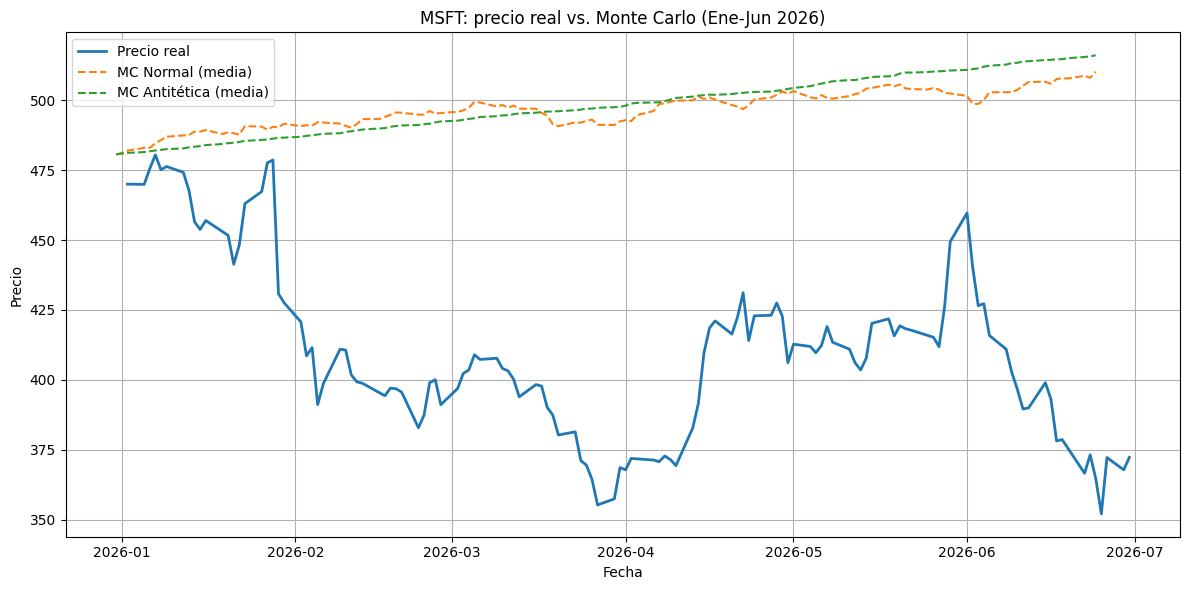

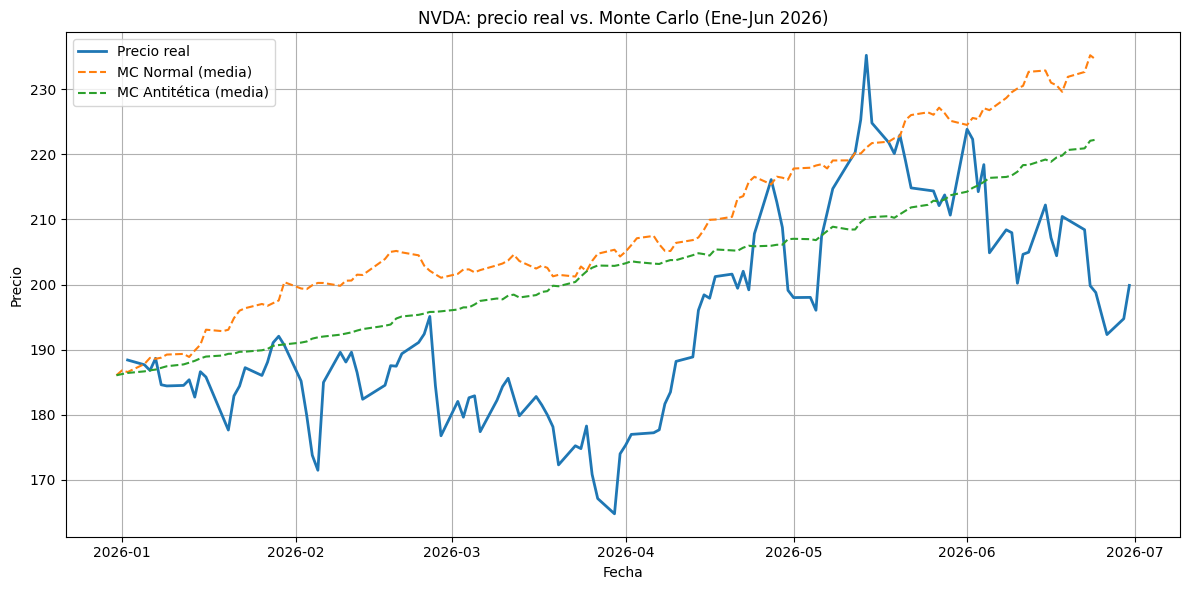

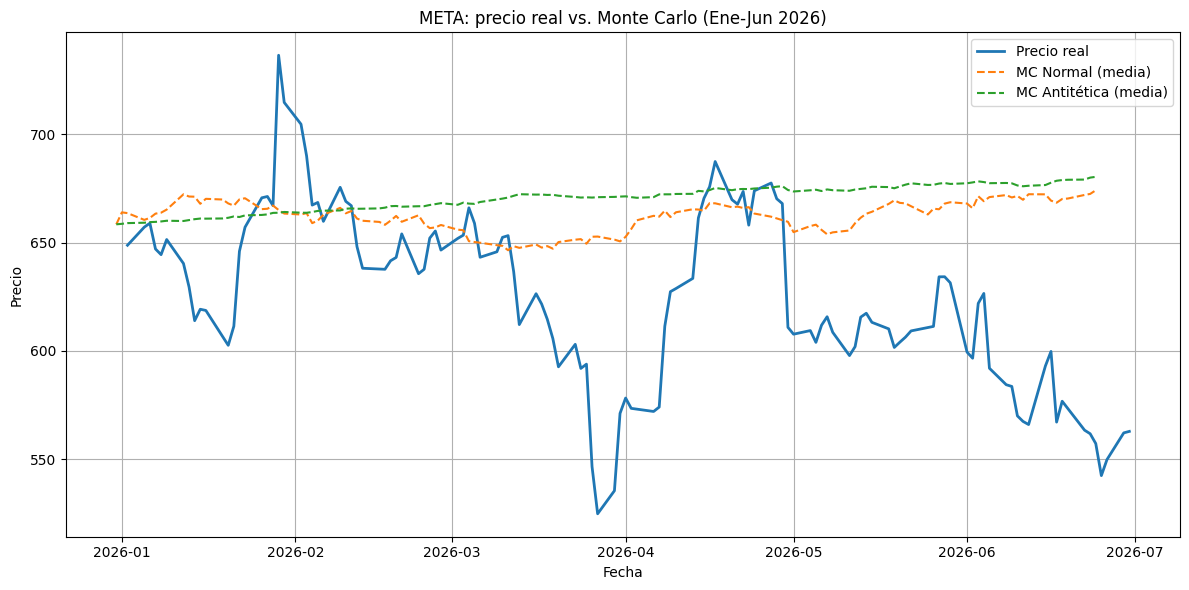

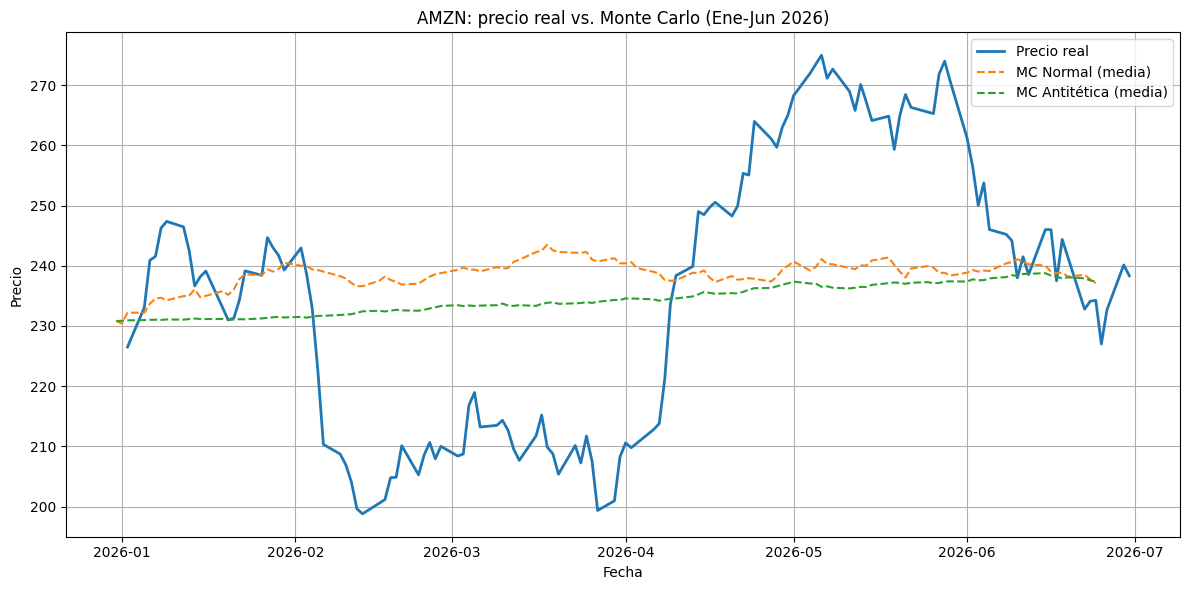

In [75]:


for ticker in tickets:
    plt.figure(figsize=(12, 6))
    plt.plot(data_real_2026.index, data_real_2026[ticker], label='Precio real', linewidth=2)
    plt.plot(fechas, rutas_normal[ticker].mean(axis=0), label='MC Normal (media)', linestyle='--')
    plt.plot(fechas, rutas_antitetica[ticker].mean(axis=0), label='MC Antitética (media)', linestyle='--')
    plt.title(f'{ticker}: precio real vs. Monte Carlo (Ene-Jun 2026)')
    plt.xlabel('Fecha')
    plt.ylabel('Precio')
    plt.legend()
    plt.grid()
    plt.tight_layout()
    plt.show()